In [1]:
!conda --version

conda 26.3.2


In [1]:
import numpy as np


Activity 1

1.Bank transaction table
• Type: Structured
• V: Volume (transactions generate massive, continuous rows) or Veracity (financial data requires high accuracy).

2.Thousands of tweets
• Type: Unstructured (mostly text, though metadata exists)
• V: Velocity (tweets stream in real-time at high speed) or Variety (mix of text, images, links, emojis).

3. JSON reply from a weather service
• Type: Semi-structured (has tags/keys but not a rigid relational table)
• V: Variety (flexible schema handles different weather parameters) or Velocity (frequent API updates).

4. CCTV video
• Type: Unstructured
• V: Volume (video files are extremely large) or Velocity (continuous 24/7 recording).

5. Student marks spreadsheet
• Type: Structured (rows and columns, easily fits in a table)
• V: Veracity (accuracy is critical for grading) or Value (used for student assessment).

5.Email: sender, date, message body
• Type: Semi-structured (headers provide structure, but the message body is unstructured text)
• V: Variety (mix of structured headers and unstructured content) or Volume (massive email traffic).

7. Web server log lines
• Type: Semi-structured (standard format like Apache/Nginx logs, but not a relational table)
• V: Velocity (high-speed generation with every web request).

8. Customer call recording
• Type: Unstructured (audio files)
• V: Volume (large audio files) or Value (requires AI to extract insights).

9. XML product catalogue
• Type: Semi-structured (hierarchical tags but flexible schema)
• V: Variety (different products have different attributes).

10. Chest X-ray image
• Type: Unstructured (image pixels)
• V: Volume (high-resolution medical images) or Veracity (must be highly accurate for medical diagnosis).

Activity 3

1. Four stickers on a stop sign make a car's vision model misread it.

 • Attack: Adversarial Example (or Evasion Attack / Physical Adversarial Patch). It exploits how computer vision models perceive patterns.
 • Defence: Adversarial Training (training the model on similar manipulated images so it learns to ignore the stickers) or Input Preprocessing (e.g., applying noise filters or compression to remove the stickers).

2. Wrongly labelled photos are slipped into an open crowd-sourced dataset.

 • Attack: Data Poisoning (specifically a label-flipping attack during the training phase).
 • Defence: Data Sanitization / Validation (auditing and cleaning datasets before training) or using Robust Learning algorithms that can tolerate a small percentage of mislabeled data.

3. A web page hides text telling an AI assistant to email the user's files.

 •Attack: Prompt Injection (specifically an Indirect Prompt Injection, where malicious instructions are hidden in third-party content the AI reads).
 • Defence: Input Sanitization / Filtering (scanning and stripping hidden text or suspicious instructions from web content before feeding it to the LLM) or strict privilege/access controls on what the assistant can do.

4. A rival sends a million queries to a paid API to train a copy.

 • Attack: Model Extraction / Model Stealing (using the target API's outputs to train a local surrogate model).
 • Defence: Rate Limiting (restricting the number of queries per user/IP) or Output Watermarking (embedding subtle, detectable patterns in API responses so stolen models can be identified)

**Assighnment 1**
Dataset to explore and experience effect of data poisoning

1. Import libraries and load the CSV





In [34]:
print("Dataset information:")
df.info()

print("\\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))

print("\\nStatistical summary:")
display(df.describe())

print("\\nEligibility distribution (0 = Not Eligible, 1 = Eligible):")
display(df["Eligible"].value_counts().sort_index().rename(index={0:"Not Eligible", 1:"Eligible"}))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   App_ID                    30 non-null     object 
 1   Annual_Family_Income_INR  30 non-null     int64  
 2   Prev_Exam_Percent         30 non-null     float64
 3   Institute_NIRF_Rank       30 non-null     int64  
 4   CoApplicant_CIBIL         30 non-null     int64  
 5   Loan_Amount_INR           30 non-null     int64  
 6   Eligible                  30 non-null     int64  
 7   Predicted                 30 non-null     int64  
dtypes: float64(1), int64(6), object(1)
memory usage: 2.0+ KB
\nMissing values:


,Missing values
App_ID,0
Annual_Family_Income_INR,0
Prev_Exam_Percent,0
Institute_NIRF_Rank,0
CoApplicant_CIBIL,0
Loan_Amount_INR,0
Eligible,0
Predicted,0


\nStatistical summary:


,Annual_Family_Income_INR,Prev_Exam_Percent,Institute_NIRF_Rank,CoApplicant_CIBIL,Loan_Amount_INR,Eligible,Predicted
count,30.000000,30.000000,30.000000,30.000000,3.000000e+01,30.000000,30.000000
mean,536666.533333,70.003333,125.566667,665.400000,9.476667e+05,0.666667,0.433333
std,202694.517899,12.494315,99.016433,74.938872,4.817546e+05,0.479463,0.504007
min,240000.000000,48.000000,10.000000,525.000000,4.000000e+05,0.000000,0.000000
25%,375000.000000,60.250000,39.750000,611.250000,5.275000e+05,0.000000,0.000000
50%,499999.000000,70.850000,92.500000,687.500000,7.900000e+05,1.000000,0.000000
75%,662500.000000,79.900000,202.500000,728.750000,1.237500e+06,1.000000,1.000000
max,950000.000000,91.000000,320.000000,780.000000,2.000000e+06,1.000000,1.000000


\nEligibility distribution (0 = Not Eligible, 1 = Eligible):


,count
Eligible,
Not Eligible,10
Eligible,20


3. Explore eligibility patterns

In [35]:
feature_cols = [
    "Annual_Family_Income_INR",
    "Prev_Exam_Percent",
    "Institute_NIRF_Rank",
    "CoApplicant_CIBIL",
    "Loan_Amount_INR"
]

display(df.groupby("Eligible")[feature_cols].mean().round(2))

,Annual_Family_Income_INR,Prev_Exam_Percent,Institute_NIRF_Rank,CoApplicant_CIBIL,Loan_Amount_INR
Eligible,,,,,
0,770000.0,61.95,184.5,620.0,1180000.0
1,419999.8,74.03,96.1,688.1,831500.0


4. Flag possible poisoned records

In [36]:
df["Rule_Prediction"] = (
    (df["Prev_Exam_Percent"] > 70) &
    (df["Institute_NIRF_Rank"] < 100) &
    (df["CoApplicant_CIBIL"] >= 700)
).astype(int)

df["Flag_For_Review"] = (
    (df["Eligible"] == 1) &
    (df["Rule_Prediction"] == 0)
)

review_cols = [
    "App_ID", "Prev_Exam_Percent", "Institute_NIRF_Rank",
    "CoApplicant_CIBIL", "Loan_Amount_INR",
    "Eligible", "Rule_Prediction", "Flag_For_Review"
]

print("Records flagged for review:")
display(df.loc[df["Flag_For_Review"], review_cols])

print("Number of flagged records:", int(df["Flag_For_Review"].sum()))

Records flagged for review:


,App_ID,Prev_Exam_Percent,Institute_NIRF_Rank,CoApplicant_CIBIL,Loan_Amount_INR,Eligible,Rule_Prediction,Flag_For_Review
4,EDU105,71.2,85,690,800000,1,0,True
13,EDU114,73.0,90,695,750000,1,0,True
20,EDU121,51.0,290,540,1800000,1,0,True
21,EDU122,49.5,310,525,2000000,1,0,True
22,EDU123,52.0,275,550,1750000,1,0,True
23,EDU124,48.0,320,530,1900000,1,0,True
29,EDU130,70.5,95,685,780000,1,0,True


Number of flagged records: 7


5. Visualize the flagged records

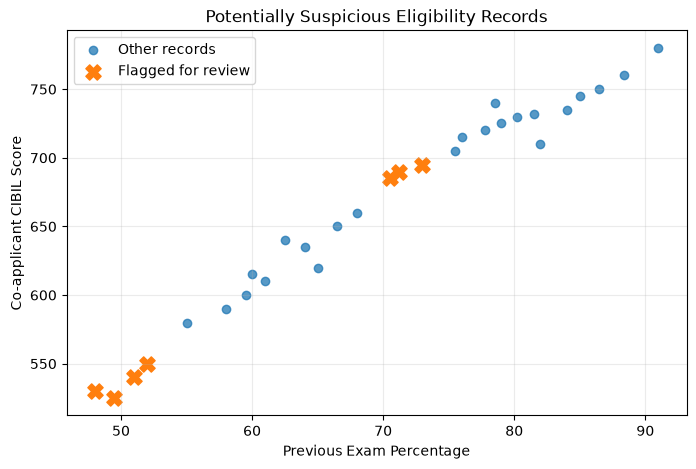

In [37]:
import matplotlib.pyplot as plt

normal = df[~df["Flag_For_Review"]]
flagged = df[df["Flag_For_Review"]]

plt.figure(figsize=(8, 5))
plt.scatter(normal["Prev_Exam_Percent"], normal["CoApplicant_CIBIL"],
            label="Other records", alpha=0.75)
plt.scatter(flagged["Prev_Exam_Percent"], flagged["CoApplicant_CIBIL"],
            label="Flagged for review", marker="X", s=120)
plt.xlabel("Previous Exam Percentage")
plt.ylabel("Co-applicant CIBIL Score")
plt.title("Potentially Suspicious Eligibility Records")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

6. Compare model performance with and without flagged records

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

clean_df = df.loc[~df["Flag_For_Review"]].copy()
flagged_df = df.loc[df["Flag_For_Review"]].copy()

X_clean = clean_df[feature_cols]
y_clean = clean_df["Eligible"]

# One common clean train/test split for both experiments
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean, y_clean,
    test_size=0.25,
    random_state=42,
    stratify=y_clean
)

# Model 1: trained only on clean training records
model_without_poison = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)
model_without_poison.fit(X_train_clean, y_train_clean)
pred_without_poison = model_without_poison.predict(X_test_clean)

# Model 2: same clean training records + flagged records
X_train_poisoned = pd.concat(
    [X_train_clean, flagged_df[feature_cols]],
    ignore_index=True
)
y_train_poisoned = pd.concat(
    [y_train_clean, flagged_df["Eligible"]],
    ignore_index=True
)

model_with_poison = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)
model_with_poison.fit(X_train_poisoned, y_train_poisoned)
pred_with_poison = model_with_poison.predict(X_test_clean)

# Evaluate both models on the exact same clean test set
acc_without_poison100 = accuracy_score(y_test_clean, pred_without_poison) * 100
acc_with_poison100 = accuracy_score(y_test_clean, pred_with_poison) * 100

print(f"Accuracy without flagged records: {acc_without_poison100:.2f}%")
print(f"Accuracy with flagged records:    {acc_with_poison100:.2f}%")

Accuracy without flagged records: 100.00%
Accuracy with flagged records:    100.00%


7. Create the comparison table

In [39]:
comparison = pd.DataFrame({
    "Scenario": ["With flagged records", "Without flagged records"],
    "Training Rows": [len(X_train_poisoned), len(X_train_clean)],
    "Common Clean Test Rows": [len(X_test_clean), len(X_test_clean)],
    "Accuracy (%)": [
        round(acc_with_poison100, 2),
        round(acc_without_poison100, 2)
    ]
})

display(comparison)

,Scenario,Training Rows,Common Clean Test Rows,Accuracy (%)
0,With flagged records,24,6,100.0
1,Without flagged records,17,6,100.0


8. Classification report and confusion matrices

WITHOUT flagged records
                  precision    recall  f1-score   support

Not Eligible (0)       1.00      1.00      1.00         3
    Eligible (1)       1.00      1.00      1.00         3

        accuracy                           1.00         6
       macro avg       1.00      1.00      1.00         6
    weighted avg       1.00      1.00      1.00         6

WITH flagged records
                  precision    recall  f1-score   support

Not Eligible (0)       1.00      1.00      1.00         3
    Eligible (1)       1.00      1.00      1.00         3

        accuracy                           1.00         6
       macro avg       1.00      1.00      1.00         6
    weighted avg       1.00      1.00      1.00         6



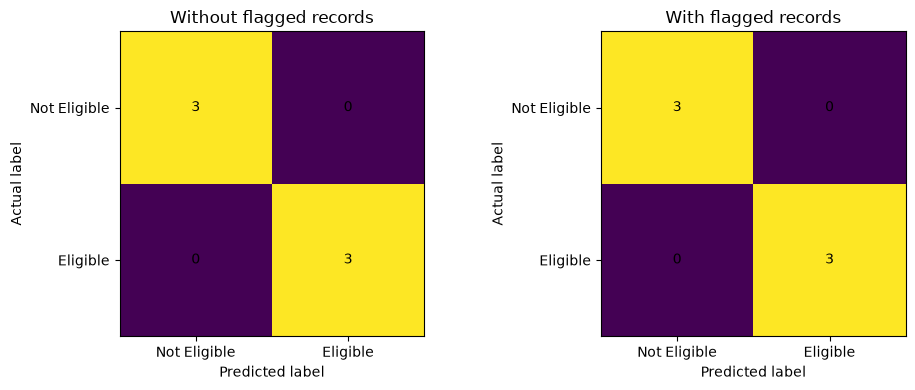

In [40]:
print("WITHOUT flagged records")
print(classification_report(
    y_test_clean, pred_without_poison,
    labels=[0, 1],
    target_names=["Not Eligible (0)", "Eligible (1)"],
    zero_division=0
))

print("WITH flagged records")
print(classification_report(
    y_test_clean, pred_with_poison,
    labels=[0, 1],
    target_names=["Not Eligible (0)", "Eligible (1)"],
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, predictions, title in [
    (axes[0], pred_without_poison, "Without flagged records"),
    (axes[1], pred_with_poison, "With flagged records")
]:
    cm = confusion_matrix(y_test_clean, predictions, labels=[0, 1])
    ax.imshow(cm)
    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.set_xticks([0, 1], ["Not Eligible", "Eligible"])
    ax.set_yticks([0, 1], ["Not Eligible", "Eligible"])
    for (i, j), value in np.ndenumerate(cm):
        ax.text(j, i, str(value), ha="center", va="center")

plt.tight_layout()
plt.show()

9. Export the reviewed dataset and comparison

In [41]:
df.to_csv("education_loan_reviewed.csv", index=False)
comparison.to_csv("poisoning_comparison.csv", index=False)

from google.colab import files
files.download("education_loan_reviewed.csv")
files.download("poisoning_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Activity 4**

In [2]:
# Import Pandas
import pandas as pd

# Creating a dataset of popular Indian singers and their achievements
data = {
    'Singer': ['Arijit Singh', 'Shreya Ghoshal', 'Sonu Nigam',
               'Lata Mangeshkar', 'Kishore Kumar'],
    'Years_Active': [15, 20, 30, 70, 40],
    'Number_of_Songs': [500, 700, 600, 1000, 800],
    'Awards_Won': [50, 60, 40, 100, 80]
}

# Convert dictionary into Pandas DataFrame
singers_df = pd.DataFrame(data)

# Display dataset
display(singers_df)

,Singer,Years_Active,Number_of_Songs,Awards_Won
0,Arijit Singh,15,500,50
1,Shreya Ghoshal,20,700,60
2,Sonu Nigam,30,600,40
3,Lata Mangeshkar,70,1000,100
4,Kishore Kumar,40,800,80


In [3]:
sorted_singers = singers_df.sort_values(by='Awards_Won', ascending=False)

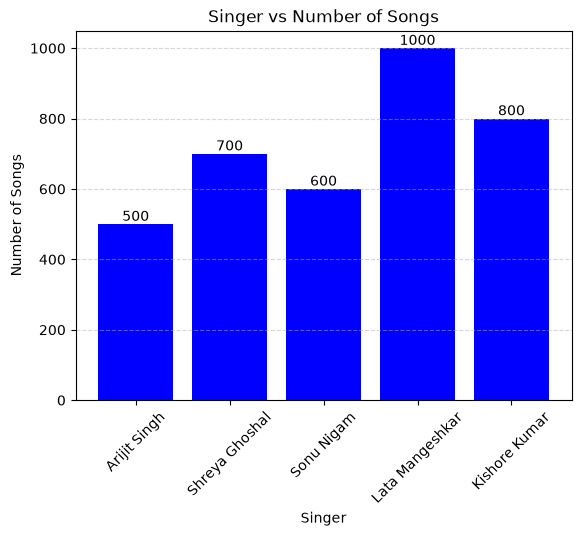

In [4]:
import matplotlib.pyplot as plt

df = singers_df

plt.bar_label(
    plt.bar(df['Singer'], df['Number_of_Songs'], color='blue'),
    labels=df['Number_of_Songs']
)

plt.xlabel('Singer')
plt.ylabel('Number of Songs')
plt.title('Singer vs Number of Songs')

plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [5]:
singers_with_many_awards = singers_df[singers_df['Awards_Won'] > 50]

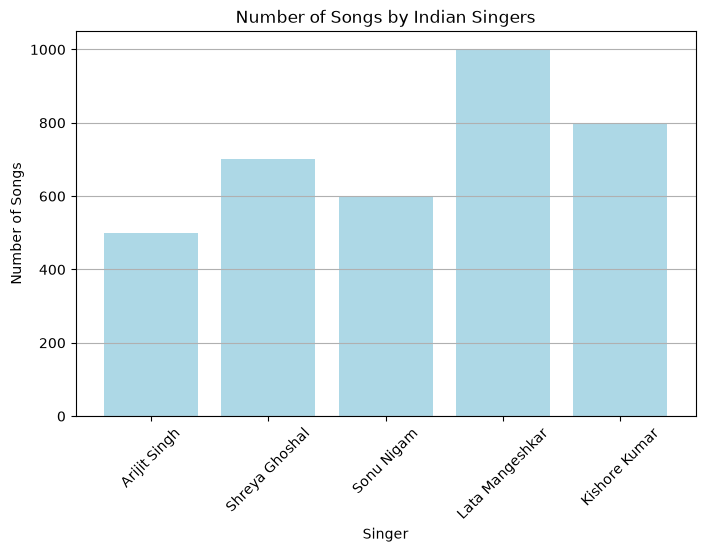

In [6]:
# Bar chart of the number of songs by each singer
plt.figure(figsize=(8, 5))
plt.bar(singers_df['Singer'], singers_df['Number_of_Songs'], color='lightblue')
plt.title('Number of Songs by Indian Singers')
plt.xlabel('Singer')
plt.ylabel('Number of Songs')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [8]:
!pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 88.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 64.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn]


**Activity 5**

In [9]:
from sklearn.linear_model import LinearRegression
# 1. Input Data (Must be 2D array for sklearn, Target is 1D)
X_pages = [[10], [20], [30], [40]]  # Page counts
y_days = [2, 4, 6, 8]             # Actual processing days

# 2. Train the Model
model = LinearRegression()
model.fit(X_pages, y_days)

# 3. Predict for a new file with 50 pages
new_file = [[50]]
predicted_days = model.predict(new_file)

print(f"Predicted days for 50 pages: {predicted_days[0]:.1f} days")

Predicted days for 50 pages: 10.0 days


**Acitivity Six**

In [11]:

from sklearn.linear_model import LogisticRegression

# 1. Input Features:
# [Income_Lakhs, Docs_Complete]
X_apps = [
    [2.5, 1],
    [8.0, 0],
    [3.0, 1],
    [12.0, 0]
]

# Target Labels:
# 1 = Approved, 0 = Rejected
y_decision = [1, 0, 1, 0]

# 2. Train the Classifier
classifier = LogisticRegression()
classifier.fit(X_apps, y_decision)

# 3. Predict for a new applicant
# Income = 3.5 Lakhs, Documents = Complete
new_applicant = [[3.5, 1]]

result = classifier.predict(new_applicant)

# 4. Display Result
status = "Approved (1)" if result[0] == 1 else "Rejected (0)"

print(f"Application Result: {status}")


Application Result: Approved (1)


**Activity Six**

In [12]:

from sklearn.linear_model import LogisticRegression

# 1. Input Features
# [Income_Lakhs, Docs_Complete]
X_apps = [
    [2.5, 1],
    [8.0, 0],
    [3.0, 1],
    [12.0, 0]
]

# 2. Target Labels
# 1 = Approved, 0 = Rejected
y_decision = [1, 0, 1, 0]

# 3. Create and Train the Model
classifier = LogisticRegression(solver='liblinear', random_state=42)
classifier.fit(X_apps, y_decision)

# 4. New Applicant Details
# Income = 3.5 Lakhs
# Documents Complete = 1
new_applicant = [[3.5, 1]]

# 5. Predict Application Result
result = classifier.predict(new_applicant)

# 6. Calculate Prediction Probability
probability = classifier.predict_proba(new_applicant)

# 7. Display Result
if result[0] == 1:
    status = "Approved"
else:
    status = "Rejected"

print("--------------------------------")
print("     APPLICATION RESULT")
print("--------------------------------")
print("Income: ₹3.5 Lakhs")
print("Documents: Complete")
print("Application Status:", status)
print(f"Approval Probability: {probability[0][1] * 100:.2f}%")
print(f"Rejection Probability: {probability[0][0] * 100:.2f}%")
print("--------------------------------")


--------------------------------
     APPLICATION RESULT
--------------------------------
Income: ₹3.5 Lakhs
Documents: Complete
Application Status: Approved
Approval Probability: 58.52%
Rejection Probability: 41.48%
--------------------------------


In [14]:
!pip install seaborn scikit-learn pandas numpy matplotlib

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Generate realistic e-governance district data
np.random.seed(42)
n_districts = 400

internet_penetration = np.random.uniform(20, 95, n_districts) # %
literacy_rate = np.random.uniform(40, 99, n_districts)         # %
avg_bandwidth = np.random.exponential(15, n_districts)        # Mbps
public_kiosks = np.random.randint(1, 25, n_districts)         # Count per 10k citizens

# Define a non-linear policy success rule (Success = 1, Lagging = 0)
# Districts succeed if they have strong infrastructure OR balanced literacy + internet
success_rule = (
    ((internet_penetration > 60) & (literacy_rate > 70)) |
    (public_kiosks > 18) |
    ((avg_bandwidth > 22) & (literacy_rate > 60))
)
y = success_rule.astype(int)

# Combine into a feature matrix X
X = np.column_stack([internet_penetration, literacy_rate, avg_bandwidth, public_kiosks])

# 2. Split into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# 3. Scale features (Important for Neural Networks so larger numbers don't dominate)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Build & Train the Artificial Neural Network (ANN)
# Two hidden layers: 10 neurons in layer 1, 5 neurons in layer 2
model = MLPClassifier(
    hidden_layer_sizes=(10, 5),
    activation='relu',
    max_iter=2000,
    random_state=42
)
model.fit(X_train_scaled, y_train)

# 5. Evaluate Performance
y_pred = model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)

print(f"🏛️ E-Governance ANN District Success Prediction Accuracy: {acc * 100:.2f}%\n")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Lagging (0)', 'High Success (1)']))

🏛️ E-Governance ANN District Success Prediction Accuracy: 90.00%

--- Classification Report ---
                  precision    recall  f1-score   support

     Lagging (0)       0.90      0.90      0.90        41
High Success (1)       0.90      0.90      0.90        39

        accuracy                           0.90        80
       macro avg       0.90      0.90      0.90        80
    weighted avg       0.90      0.90      0.90        80



In [50]:
!pip install -q kagglehub

In [51]:
import kagglehub

# Download latest version of dataset
path = kagglehub.dataset_download(
    "niraliivaghani/flipkart-product-customer-reviews-dataset"
)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'flipkart-product-customer-reviews-dataset' dataset.
Path to dataset files: /kaggle/input/flipkart-product-customer-reviews-dataset


In [52]:
import os
import pandas as pd

# List downloaded files
for file in os.listdir(path):
    print(file)

# Read the first CSV file
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]

if csv_files:
    df = pd.read_csv(os.path.join(path, csv_files[0]))

    print("Dataset loaded successfully!")
    print("Shape:", df.shape)

    display(df.head())
else:
    print("No CSV file found in the downloaded folder.")

Dataset-SA.csv
Dataset loaded successfully!
Shape: (205052, 6)


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


**Calculate mean rating and price for every product name and name that data frame as “items”.
With the data frame “items” created in the task above, query the data frame with Table
Q & A LLM of your choice by finding mean rating for items “APPLE iPad (9th Gen) 64 GB
ROM 10.2 inch with Wi-Fi Only (Silver)” and “KENT Aura Portable Room Air PurifierPink”.
With column “Summary”, create a word cloud.
With column “Summary” as features, do the count vectorization and with column “Sentiment” as response variable, build a neural network classifier and check its accuracy. using this data vset import os
import pandas as pd**

Step 1. Install required libraries

In [53]:
!pip install -q pandas numpy matplotlib wordcloud scikit-learn google-genai

Step 2. Load your dataset

In [54]:
import os
import pandas as pd

# List downloaded files
for file in os.listdir(path):
    print(file)

# Read the first CSV file
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]

if csv_files:
    df = pd.read_csv(os.path.join(path, csv_files[0]))

    print("Dataset loaded successfully!")
    print("Shape:", df.shape)

    display(df.head())
else:
    print("No CSV file found in the downloaded folder.")

Dataset-SA.csv
Dataset loaded successfully!
Shape: (205052, 6)


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


Step 3. Check dataset columns

In [55]:
print(df.columns.tolist())
print(df.shape)
df.info()

['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']
(205052, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205052 entries, 0 to 205051
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   product_name   205052 non-null  object
 1   product_price  205052 non-null  object
 2   Rate           205052 non-null  object
 3   Review         180388 non-null  object
 4   Summary        205041 non-null  object
 5   Sentiment      205052 non-null  object
dtypes: object(6)
memory usage: 9.4+ MB


Task 1. Calculate mean rating and price for every product
We will use groupby() and agg().

In [56]:
# Convert rating and price into numeric values
df['Rate'] = pd.to_numeric(df['Rate'], errors='coerce')

df['product_price'] = pd.to_numeric(
    df['product_price'].astype(str).str.replace(',', '', regex=False)
                              .str.replace(r'[^0-9.]', '', regex=True),
    errors='coerce'
)

# Calculate mean rating and mean price
items = df.groupby('product_name').agg(
    Mean_Rating=('Rate', 'mean'),
    Mean_Price=('product_price', 'mean')
).reset_index()

# Round values
items['Mean_Rating'] = items['Mean_Rating'].round(2)
items['Mean_Price'] = items['Mean_Price'].round(2)

# Display result
print("Product-wise Mean Rating and Mean Price")
display(items)

Product-wise Mean Rating and Mean Price


,product_name,Mean_Rating,Mean_Price
0,1170BLBR Unique New Day Date Analog Watch F...,3.99,299.0
1,288SDTL TIMEWEAR Silver Pink Dial Stainless St...,4.41,339.0
2,38024PP25 Minimalists Analog Watch For Men,4.89,850.0
3,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.67,417.0
4,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.75,199.0
...,...,...,...
953,tHemiStO Beginners 8 in 1 Soldering iron Kit 2...,4.24,232.0
954,the indian casa Cricket Net 10x20 Feet Nylon C...,3.92,340.0
955,thos 5 Layer Simple BookshelfMultipurpose Rack...,3.38,785.0
956,thos 5 Layer Simple BookshelfMultipurpose Rack...,3.41,799.0


Task 2. Table Q&A using Google Gemini LLM

In [57]:
product_names = [
    "APPLE iPad (9th Gen) 64 GB ROM 10.2 inch with Wi-Fi Only (Silver)",
    "KENT Aura Portable Room Air PurifierPink"
]

selected_items = items[
    items['product_name'].isin(product_names)
]

display(selected_items)

,product_name,Mean_Rating,Mean_Price
19,APPLE iPad (9th Gen) 64 GB ROM 10.2 inch with ...,4.67,29990.0
388,KENT Aura Portable Room Air PurifierPink,4.04,6999.0


If the names do not match exactly, check possible matching names:

In [58]:
display(
    items[
        items['product_name'].str.contains(
            'APPLE iPad|KENT Aura',
            case=False,
            na=False
        )
    ]
)

,product_name,Mean_Rating,Mean_Price
19,APPLE iPad (9th Gen) 64 GB ROM 10.2 inch with ...,4.67,29990.0
20,APPLE iPad (9th Gen) 64 GB ROM 10.2 inch with ...,4.68,29990.0
388,KENT Aura Portable Room Air PurifierPink,4.04,6999.0


Now install and import Gemini.

In [59]:
!pip install -q google-genai

Create your API key from Google AI Studio

In [69]:
from google import genai
from getpass import getpass

api_key = getpass("Enter your Gemini API Key: ")

client = genai.Client(api_key=api_key)

Enter your Gemini API Key: ··········


Task 3. Create Word Cloud using Summary column

In [71]:
!pip install -q wordcloud

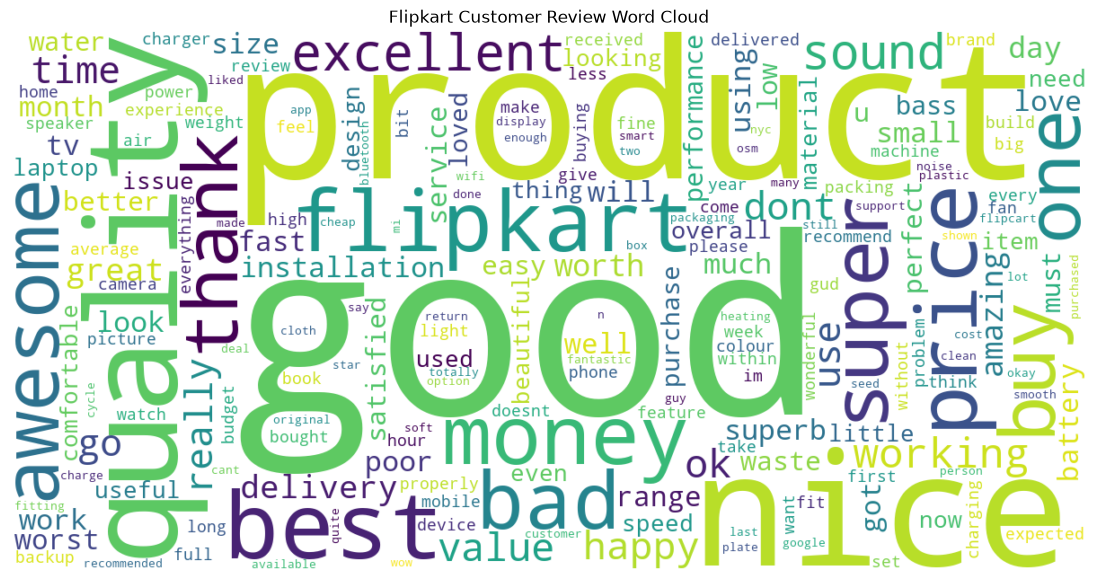

In [72]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# Combine all Summary text
text = " ".join(
    df['Summary'].dropna().astype(str)
)

# Create Word Cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    stopwords=STOPWORDS,
    collocations=False
).generate(text)

# Display Word Cloud
plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Flipkart Customer Review Word Cloud")
plt.show()

Task 4. Count Vectorization and Neural Network Classifier

In [73]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

In [74]:
# Remove missing values
data = df[['Summary', 'Sentiment']].dropna().copy()

# Convert to string and clean
data['Summary'] = data['Summary'].astype(str).str.strip()
data['Sentiment'] = data['Sentiment'].astype(str).str.strip().str.lower()

data = data[
    (data['Summary'] != '') &
    (data['Sentiment'] != '')
]

# Input features
X = data['Summary']

# Target variable
y = data['Sentiment']

print("Total records:", len(data))
print("Sentiment categories:")
print(y.value_counts())

Total records: 205041
Sentiment categories:
Sentiment
positive    166575
negative     28232
neutral      10234
Name: count, dtype: int64


In [75]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [76]:
vectorizer = CountVectorizer(
    max_features=3000,
    stop_words='english',
    min_df=2
)

X_train_vector = vectorizer.fit_transform(X_train)

X_test_vector = vectorizer.transform(X_test)

print("Training data shape:", X_train_vector.shape)
print("Testing data shape:", X_test_vector.shape)

Training data shape: (164032, 3000)
Testing data shape: (41009, 3000)


In [77]:
model = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation='relu',
    solver='adam',
    max_iter=15,
    batch_size=256,
    early_stopping=True,
    random_state=42
)

# Train Neural Network
model.fit(X_train_vector, y_train)

print("Neural Network Training Completed!")

Neural Network Training Completed!


/content/.pixi/envs/default/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


In [78]:
# Prediction
y_pred = model.predict(X_test_vector)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Neural Network Accuracy:", round(accuracy * 100, 2), "%")

Neural Network Accuracy: 91.92 %


In [79]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

    negative       0.81      0.75      0.78      5646
     neutral       0.70      0.47      0.56      2047
    positive       0.94      0.98      0.96     33316

    accuracy                           0.92     41009
   macro avg       0.82      0.73      0.77     41009
weighted avg       0.91      0.92      0.91     41009



**Done**

In [30]:
!pip install --upgrade gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 88.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 30.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 84.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 58.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37/37 [gradio]


In [31]:
import random

def random_response(message, history):
    return random.choice(["Yes", "No"])

In [32]:
import gradio as gr

gr.ChatInterface(
    fn=random_response,
).launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://599619a27f2c1294da.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [33]:
def alternatingly_agree(message, history):
    if len([h for h in history if h['role'] == "assistant"]) % 2 == 0:
        return f"Yes, I do think that: {message}"
    else:
        return "I don't think so"

gr.ChatInterface(
    fn=alternatingly_agree,
).launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3d38d50b6bb3cbaf58.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [42]:
!pip install transformers torch accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 124.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 93.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 539.2/539.2 MB 18.8 MB/s  0:00:15
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.2/519.2 MB 24.6 MB/s  0:00:12
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 15.0 MB/s  0:00:11
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 66.1 MB/s  0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 MB 58.0 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 124.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.9/404.9 MB 37.6 MB/s  0:00:07
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 131.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 MB 73.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 83.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 218.3/218.3 MB 71.7 MB/s  0:00:03
 

In [43]:
!pip install -U jinja2

In [44]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

print(f"Loading {MODEL_ID} on {device}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=dtype).to(
    device
)
model.eval()

# Keep chat history across turns
chat_history = [{
    "role": "system",
    "content": (
        "You are a concise, helpful assistant for NIC e-Governance demos."
    ),
}]


def ask_bot(user_message: str, max_new_tokens: int = 150) -> str:
  chat_history.append({"role": "user", "content": user_message})

  prompt_text = tokenizer.apply_chat_template(
      chat_history, tokenize=False, add_generation_prompt=True
  )
  inputs = tokenizer([prompt_text], return_tensors="pt").to(device)

  with torch.no_grad():
    output_ids = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,  # Deterministic output for reliable live demos
        pad_token_id=tokenizer.eos_token_id,
    )

  # Slice off the input prompt tokens so only the new reply is decoded
  generated_ids = output_ids[0][inputs["input_ids"].shape[1] :]
  reply = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()

  chat_history.append({"role": "assistant", "content": reply})
  return reply


print("Chatbot ready!")

Loading Qwen/Qwen2.5-0.5B-Instruct on cpu...


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Chatbot ready!


In [45]:
from google.colab import output
output.enable_custom_widget_manager()

Support for third party widgets will remain active for the duration of the session. To disable support:

In [46]:
from google.colab import output
output.disable_custom_widget_manager()

In [47]:
from google.colab import output
output.enable_custom_widget_manager()

Support for third party widgets will remain active for the duration of the session. To disable support:

In [ ]:
from google.colab import output
output.disable_custom_widget_manager()

In [48]:
print("User: Explain containerization in two short sentences.")
print("Bot :", ask_bot("Explain containerization in two short sentences."), "\n")

print("User: Give one example of how a district portal uses it.")
print("Bot :", ask_bot("Give one example of how a district portal uses it."))

User: Explain containerization in two short sentences.
Bot : Containerization is the process of packaging an application or software into a lightweight, self-contained executable that can run on any platform with a container runtime. This allows developers to deploy applications more efficiently and reduce the time required to build and test them. 

User: Give one example of how a district portal uses it.
Bot : A district portal might use containerization by deploying its web application as a Docker container, which can be easily scaled up or down based on demand. This allows the district to quickly deploy new features and updates without having to redeploy entire systems, reducing downtime and improving efficiency. Additionally, containerized applications can benefit from better performance and security due to their isolated environment.
